# Geospatial YOLO Pipeline — Master Visualization & Plotting Suite
This notebook consolidates all analytical, cartographic, and bounding-box plotting routines across the pipeline:
1. **Publication Cartography Suite**: High-precision metric maps (UTM Zone 33N, EPSG:32633) with scalebars, compass rose, and satellite basemap.
2. **Bounding Box & Dataset Distribution Analysis**: Foreground vs. Background, BBox Width vs. Height, log-scale area distribution, and within-tile spatial heatmaps.
3. **Extended Testset Spatial Cartography**: Zero-leakage combined test set corridor mapping, footprint overlays, and multi-temporal centroid plots.
4. **FiftyOne Interactive Ingestion**: Geospatial cohort visualization and ghost sample exploration.


## 1. Setup & Environment Configuration


In [1]:
import os
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import geopandas as gpd
import seaborn as sns
from PIL import Image

# Ensure repo root is in Python path
REPO_ROOT = Path('.').resolve()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import config
import render_dataset_maps as rdm
import plot_bbox_analysis as pba
import plot_testset_centroids as ptc

print(f'Repo Root: {REPO_ROOT}')
print(f'Data Export Dir: {config.BASE_EXPORT_DIR}')
print(f'Plots Dir: {config.PLOTS_DIR}')


Repo Root: C:\Users\emilb\Documents\GitHub\_trainer_dataset_prep
Data Export Dir: C:\Users\emilb\Documents\GitHub\_data
Plots Dir: C:\Users\emilb\Documents\GitHub\_trainer_dataset_prep\plots


## 2. Bounding Box & Dataset Distribution Analysis
Extracts YOLO labels, calculates aspect ratios, log-scale areas, and spatial distribution across image tiles.


 YOLO DATASET BOUNDING BOX & DISTRIBUTION ANALYSIS
[*] Dataset Directory: C:\Users\emilb\Documents\GitHub\_data\sliced_split_dataset
[*] Output Plots Dir:  C:\Users\emilb\Documents\GitHub\_trainer_dataset_prep\plots
[*] Detected dataset splits: train, val, test
[*] Image Resolution: 1024 x 1024 px
[*] Extracting bounding box dimensions and coordinates...

 DATASET OVERVIEW: sliced_split_dataset
  [TOTAL] Images: 6,573 | Total Bounding Boxes: 7,035
          Foreground (Positive): 3,341 | Background (Negative): 3,232
-----------------------------------------------------------------
  [TRAIN] Images: 5,553   | Boxes: 5,883   | FG: 2,698  | BG: 2,855 
  [VAL  ] Images: 510     | Boxes: 576     | FG: 328    | BG: 182   
  [TEST ] Images: 510     | Boxes: 576     | FG: 315    | BG: 195   

[SUCCESS] Saved composite dashboard: C:\Users\emilb\Documents\GitHub\_trainer_dataset_prep\plots\bbox_analysis_dashboard.png
[SUCCESS] Saved 4 individual publication figures into:
  -> plot_1_fg_bg.png
  

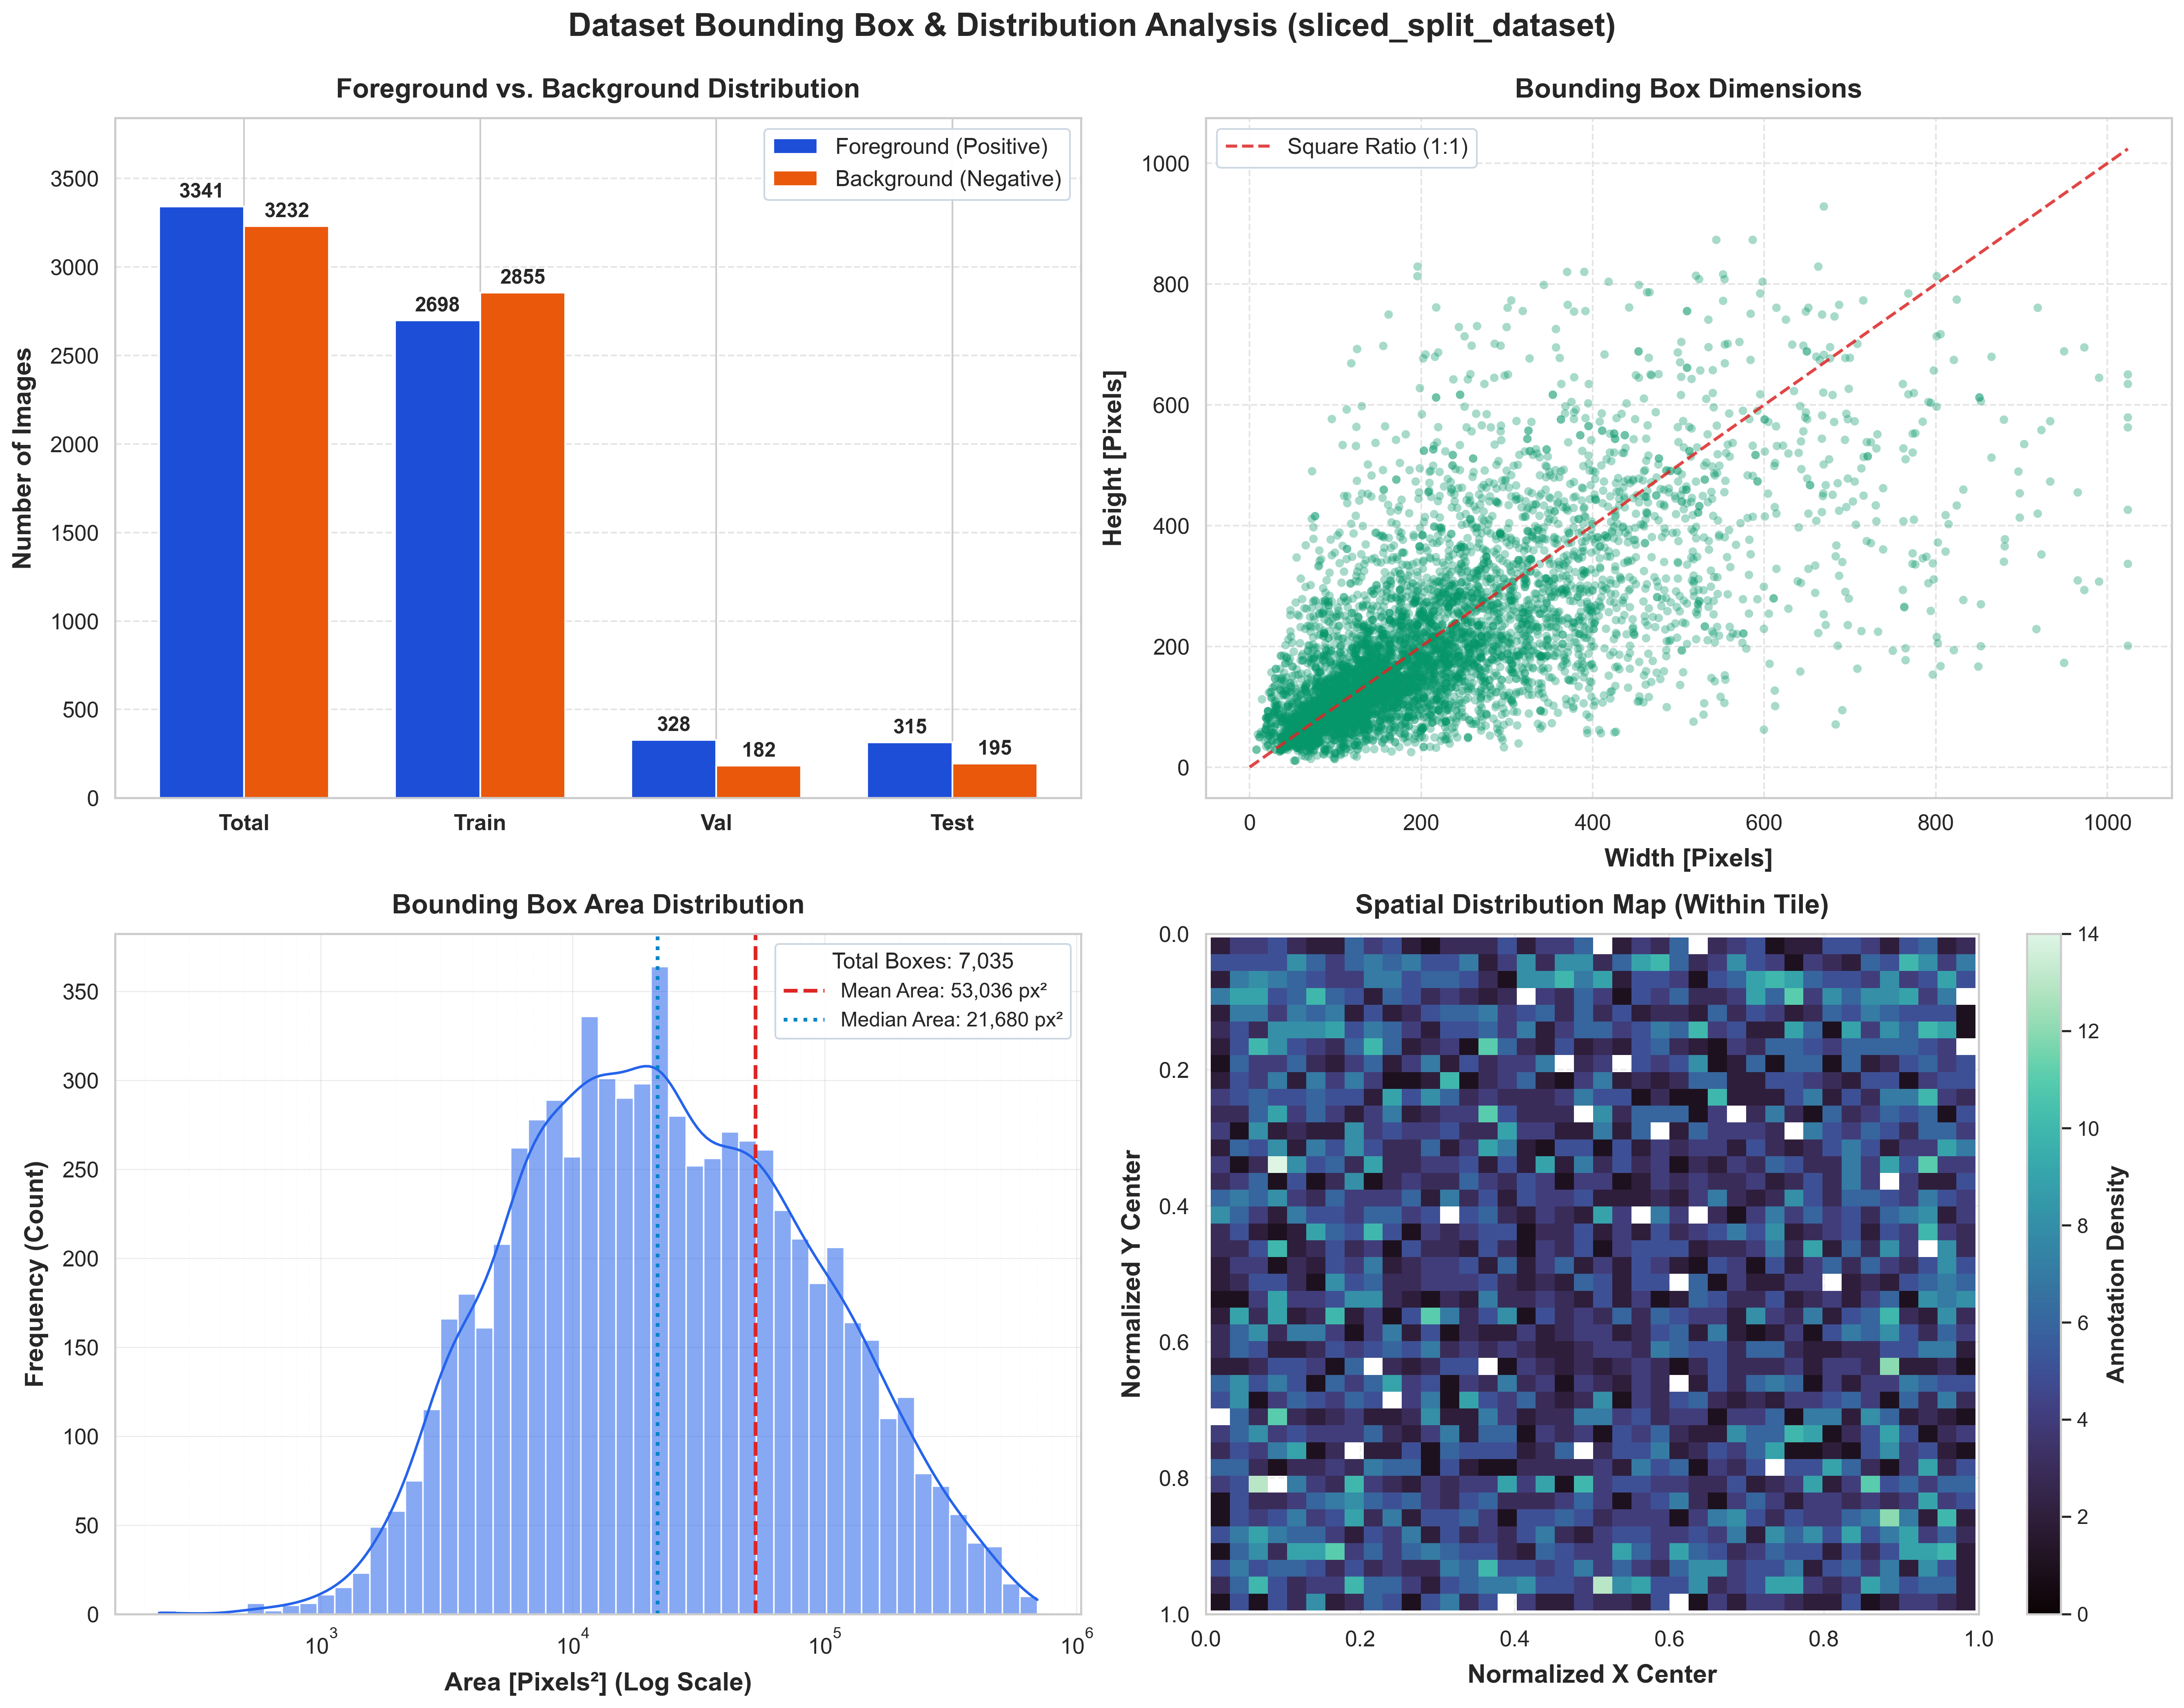

In [2]:
# Execute full BBox analytical suite
dataset_dir = config.STRAT_OUTPUT_DIR
plots_dir = config.PLOTS_DIR

dashboard_path, ind_plots = pba.render_bbox_analysis(
    dataset_dir=dataset_dir,
    plots_dir=plots_dir
)

# Display the generated dashboard
Image.open(dashboard_path)


### Individual Analytical Plots (300 DPI)


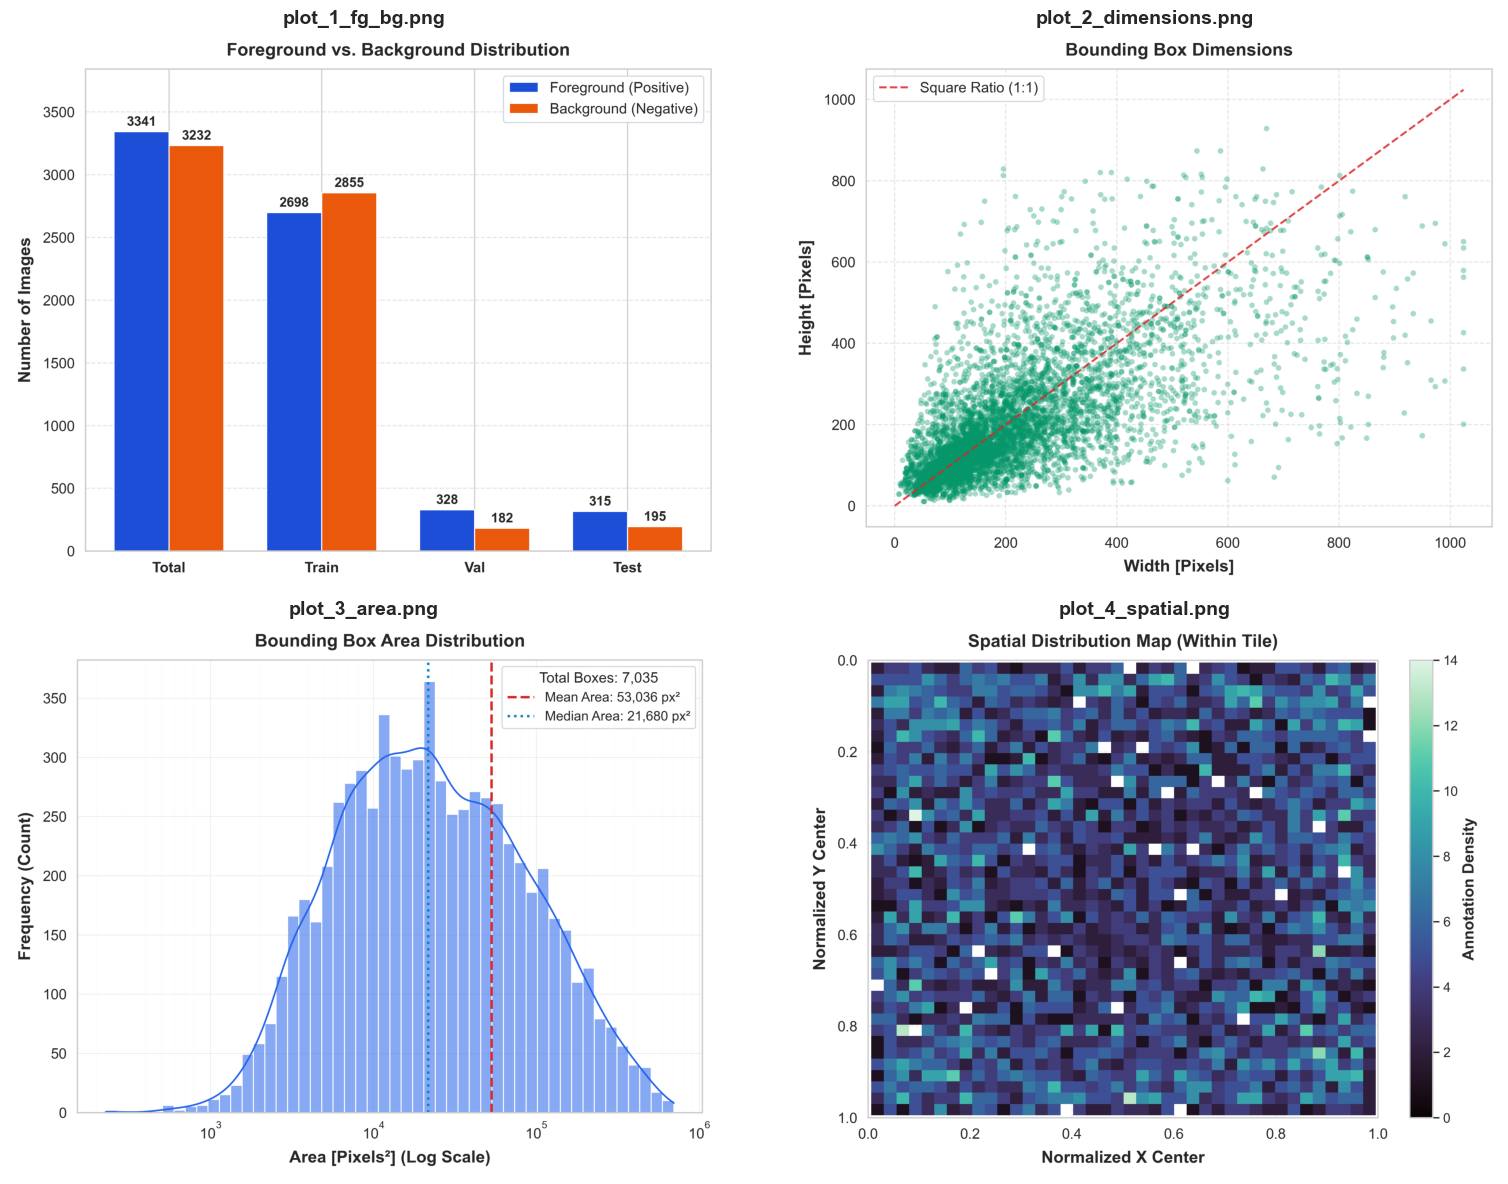

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
for ax, p in zip(axes.flatten(), ind_plots):
    img = Image.open(p)
    ax.imshow(img)
    ax.axis('off')
    ax.set_title(p.name, fontsize=14, fontweight='bold', pad=8)
plt.tight_layout()
plt.show()


## 3. Publication Cartography Suite (EPSG:32633, Fonts $\ge 16$ pt)
Generates minimalist maps with synchronized extents, true metric axes, two-tone compass roses, and Esri World Imagery.


In [4]:
# Run full cartography suite
generated_maps = rdm.render_all_publication_dataset_maps(
    export_dir=config.BASE_EXPORT_DIR,
    plots_dir=config.PLOTS_DIR,
    use_basemap=True
)


 EXECUTING PUBLICATION CARTOGRAPHY SUITE (ALL FONTS >= 16 PT)

[Map 1] Rendering Whole Dataset Splits with Dropped Buffers...
  -> Successfully generated: whole_dataset_splits_with_buffer_map.png

[Map 2] Rendering Complete Distillation Dataset Map (Train, Val, Test - No Buffer)...
  -> Distillation Train count: 5,553 slices (0 unlabeled + 5,553 labeled train)
  -> Validation count: 510 slices, Test count: 510 slices
  -> Successfully generated: distillation_dataset_map.png

[Map 3] Rendering Extended Testset Centroid Map (Original vs Extended)...
  -> Original Labeled Test Slices: 257
  -> Extended Unlabeled Slices:   4,464
  -> Successfully generated: extended_testset_centroids_map.png

[Map 4] Rendering Whole Dataset Image Locations (2023 & 2024)...
  -> Extracted 1,520 cameras for 2023, 2,082 cameras for 2024.
  -> Saved 2023 image locations: whole_dataset_images_2023_map.png
  -> Saved 2024 image locations: whole_dataset_images_2024_map.png
  -> Saved combined survey image locatio

### Display Split Maps (Whole Dataset & Distillation Pretraining)


In [ ]:
map1_path = config.PLOTS_DIR / 'whole_dataset_splits_with_buffer_map.png'
map2_path = config.PLOTS_DIR / 'distillation_dataset_map.png'

fig, axes = plt.subplots(1, 2, figsize=(20, 10))
for ax, p, title in zip(axes, [map1_path, map2_path], ['Whole Dataset Splits (with Buffer Moat)', 'Stage 1 Distillation Pretraining Set']):
    if p.exists():
        ax.imshow(Image.open(p))
        ax.axis('off')
        ax.set_title(title, fontsize=16, fontweight='bold', pad=10)
plt.tight_layout()
plt.show()


## 4. Extended Testset Spatial Cartography
Visualizes original labeled test slices vs. extended unlabeled background tiles across the railway corridor.


In [ ]:
test_map_path = rdm.render_extended_testset_blue_shades_map(
    export_dir=config.BASE_EXPORT_DIR,
    plots_dir=config.PLOTS_DIR,
    use_basemap=True
)

if test_map_path.exists():
    plt.figure(figsize=(12, 10))
    plt.imshow(Image.open(test_map_path))
    plt.axis('off')
    plt.title('Extended Testset Centroid Map (EPSG:32633)', fontsize=16, fontweight='bold', pad=10)
    plt.show()


## 5. Raw Survey Flight Paths & Selected Annotation Maps
Displays the 2023 and 2024 UAV campaigns and parent photos selected for annotation.


In [ ]:
flight_map = config.PLOTS_DIR / 'whole_dataset_images_by_year.png'
label_map = config.PLOTS_DIR / 'selected_images_for_labelling_map.png'

fig, axes = plt.subplots(1, 2, figsize=(20, 10))
for ax, p, title in zip(axes, [flight_map, label_map], ['Flight Survey Imagery (2023 vs 2024)', 'Selected Images for Annotation']):
    if p.exists():
        ax.imshow(Image.open(p))
        ax.axis('off')
        ax.set_title(title, fontsize=16, fontweight='bold', pad=10)
plt.tight_layout()
plt.show()
